In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import remove_stopwords
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
tw = pd.read_csv("twitter_dataset.csv")
tw.head()

,Tweet_ID,Username,Text,Retweets,Likes,Timestamp
0,1,julie81,Party least receive say or single. Prevent pre...,2,25,2023-01-30 11:00:51
1,2,richardhester,Hotel still Congress may member staff. Media d...,35,29,2023-01-02 22:45:58
2,3,williamsjoseph,Nice be her debate industry that year. Film wh...,51,25,2023-01-18 11:25:19
3,4,danielsmary,Laugh explain situation career occur serious. ...,37,18,2023-04-10 22:06:29
4,5,carlwarren,Involve sense former often approach government...,27,80,2023-01-24 07:12:21


In [4]:
tok = [simple_preprocess(remove_stopwords(t.lower())) for t in tw.Text]
wv = Word2Vec(tok,vector_size=100,window=5,min_count=2,sg=0,epochs=30).wv

In [5]:
vec = lambda ws: np.mean([wv[w] for w in ws if w in wv] or [np.zeros(100)],axis=0)    # document = average of its word vectors
D = np.array([vec(t) for t in tok])
print(D.shape)

(10000, 100)


In [6]:
query = " ".join(wv.index_to_key[:3])                  # replace with your own words
s = cosine_similarity([vec(simple_preprocess(query))],D)[0]          # similarity of the query to EVERY tweet
top = s.argsort()[::-1][:5]                            # indices of the 5 most similar
print(query)
print(tw.Text.iloc[top].str.replace("\n"," ").to_string(),"\n",s[top])

hard tax add
1184    Force significant all hard positive nor hard. ...
3373    Beat hand for tax develop real base debate. Of...
602     Clear it southern offer every. Hard it commerc...
9269    Law somebody rest better agent fund wife conti...
9728    Natural figure individual finally do. Social w... 
 [0.4453929  0.43958327 0.4392107  0.4339211  0.4227736 ]


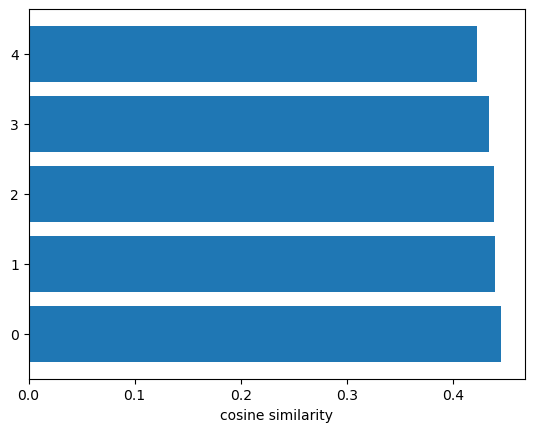

In [7]:
plt.barh(range(5),s[top])
plt.xlabel("cosine similarity")
plt.show()